<a href="https://colab.research.google.com/github/marrihruthika28/Deep-Learning/blob/main/VisionPort.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ultralytics fastapi uvicorn python-multipart opencv-python nest-asyncio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [2]:
import cv2
import numpy as np
import torch
import time
from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Image

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All libraries imported successfully!
PyTorch version: 2.14.1+cpu
OpenCV version: 5.0.0


In [3]:
print("Loading YOLOv8 Nano model...")

model = YOLO("yolov8n.pt")

print("YOLOv8 Nano model loaded successfully!")

Loading YOLOv8 Nano model...
YOLOv8 Nano model loaded successfully!


In [4]:
from fastapi import FastAPI, File, UploadFile, HTTPException
from fastapi.responses import StreamingResponse
import io
import cv2
import numpy as np
import time

app = FastAPI(title="Indian Traffic Detection API")

@app.get("/")
async def home():
    return {
        "status": "Active",
        "message": "Indian Traffic Detection API is running!"
    }

@app.get("/health")
async def health():
    return {
        "status": "Active",
        "model": "YOLOv8 Nano",
        "device": "CPU"
    }

@app.post("/detect/")
async def detect_objects(file: UploadFile = File(...)):
    try:
        contents = await file.read()

        if not contents:
            raise HTTPException(
                status_code=400,
                detail="Uploaded image is empty."
            )

        nparr = np.frombuffer(contents, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        if img is None:
            raise HTTPException(
                status_code=400,
                detail="Invalid image file."
            )

        start_time = time.time()

        results = model.predict(
            source=img,
            imgsz=416,
            conf=0.25,
            device="cpu",
            verbose=False
        )

        inference_time = time.time() - start_time

        annotated_img = results[0].plot()

        success, encoded_img = cv2.imencode(
            ".jpg", annotated_img
        )

        if not success:
            raise HTTPException(
                status_code=500,
                detail="Image encoding failed."
            )

        print("Detection completed!")
        print("Inference time:", round(inference_time, 3), "seconds")

        return StreamingResponse(
            io.BytesIO(encoded_img.tobytes()),
            media_type="image/jpeg"
        )

    except HTTPException:
        raise
    except Exception as error:
        raise HTTPException(status_code=500, detail=str(error))

print("FastAPI backend created successfully!")

FastAPI backend created successfully!


In [5]:
import nest_asyncio
import threading
import uvicorn
import time

nest_asyncio.apply()

def run_server():
    uvicorn.run(app, host="0.0.0.0", port=8000)

server_thread = threading.Thread(target=run_server, daemon=True)
server_thread.start()

time.sleep(3)

print("FastAPI server started successfully!")

INFO:     Started server process [11577]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


FastAPI server started successfully!


In [6]:
import requests

response = requests.get("http://127.0.0.1:8000/")

print(response.json())

INFO:     127.0.0.1:51280 - "GET / HTTP/1.1" 200 OK
{'status': 'Active', 'message': 'Indian Traffic Detection API is running!'}


In [7]:
response = requests.get("http://127.0.0.1:8000/health")

print(response.json())

INFO:     127.0.0.1:56854 - "GET /health HTTP/1.1" 200 OK
{'status': 'Active', 'model': 'YOLOv8 Nano', 'device': 'CPU'}


In [8]:
from IPython.display import HTML, display

frontend_html = """
<!DOCTYPE html>
<html>
<head>
<title>VisionPort - Indian Traffic Analyzer</title>

<style>
body {
    font-family: Arial;
    background: #f2f4f8;
    padding: 25px;
}
.container {
    max-width: 900px;
    margin: auto;
    background: white;
    padding: 25px;
    border-radius: 12px;
}
h1 {
    color: #183b70;
    text-align: center;
}
.card {
    display: inline-block;
    background: #eaf1ff;
    padding: 20px;
    margin: 10px;
    border-radius: 8px;
}
.upload {
    padding: 30px;
    background: #f5f7fa;
    border: 2px dashed #4b75bd;
    text-align: center;
}
img {
    max-width: 100%;
    margin-top: 20px;
}
</style>
</head>

<body>
<div class="container">

<h1>VisionPort Live Portal</h1>
<h3 style="text-align:center">Indian Traffic Analyzer</h3>

<div class="card">
<strong>System Status</strong>
<p>Active</p>
</div>

<div class="card">
<strong>Model Architecture</strong>
<p>YOLOv8 Nano</p>
</div>

<div class="card">
<strong>Inference Hardware</strong>
<p>CPU</p>
</div>

<div class="upload">
<h3>Upload Traffic Image</h3>

<input type="file" id="imageInput" accept="image/*">

<br><br>

<button onclick="detectImage()">Detect Objects</button>

<p id="status">Waiting for image...</p>
</div>

<h3>Object Detection Output</h3>
<img id="result" style="display:none">

</div>

<script>
async function detectImage() {

    const file = document.getElementById("imageInput").files[0];

    if (!file) {
        alert("Please select an image first!");
        return;
    }

    const formData = new FormData();
    formData.append("file", file);

    document.getElementById("status").innerText =
        "Processing image...";

    try {

        const response = await fetch(
            "http://127.0.0.1:8000/detect/",
            {
                method: "POST",
                body: formData
            }
        );

        if (!response.ok) {
            throw new Error(await response.text());
        }

        const blob = await response.blob();

        document.getElementById("result").src =
            URL.createObjectURL(blob);

        document.getElementById("result").style.display = "block";

        document.getElementById("status").innerText =
            "Detection completed successfully!";

    } catch(error) {

        document.getElementById("status").innerText =
            "Detection failed: " + error.message;
    }
}
</script>

</body>
</html>
"""

display(HTML(frontend_html))

In [9]:
from google.colab import files

uploaded = files.upload()

Saving traffic image.webp to traffic image.webp



image 1/1 /content/traffic image.webp: 384x640 5 cars, 303.7ms
Speed: 19.4ms preprocess, 303.7ms inference, 27.4ms postprocess per image at shape (1, 3, 384, 640)


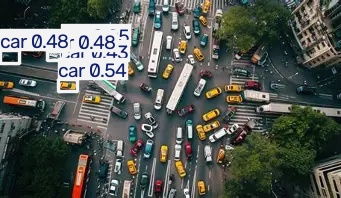

Traffic object detection completed!


In [10]:
import cv2
from IPython.display import display, Image

image_name = list(uploaded.keys())[0]

results = model.predict(
    source=image_name,
    conf=0.25,
    imgsz=640,
    device="cpu"
)

annotated_image = results[0].plot()

cv2.imwrite("traffic_result.jpg", annotated_image)

display(Image(filename="traffic_result.jpg"))

print("Traffic object detection completed!")

In [11]:
boxes = results[0].boxes

print("========== TRAFFIC ANALYSIS REPORT ==========")

print("Total Objects Detected:", len(boxes))

for class_id, count in zip(*np.unique(
    boxes.cls.cpu().numpy().astype(int),
    return_counts=True
)):
    print(model.names[class_id], ":", count)

print("==============================================")

========== TRAFFIC ANALYSIS REPORT ==========
Total Objects Detected: 5
car : 5


In [12]:
from google.colab import files

files.download("traffic_result.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
from google.colab import output

proxy_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print("Backend URL:", proxy_url)

Backend URL: https://8000-m-s-usw1c0-1rzatlqr6oqqq-c.us-west1.prod.r.colab.dev


In [14]:
import requests

response = requests.get(proxy_url)

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 404


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [15]:
import requests

print("Backend URL:", proxy_url)

response = requests.get(proxy_url + "/health")

print("Status Code:", response.status_code)
print("Content Type:", response.headers.get("content-type"))
print("Response:", response.text[:1000])

Backend URL: https://8000-m-s-usw1c0-1rzatlqr6oqqq-c.us-west1.prod.r.colab.dev
Status Code: 404
Content Type: None
Response: 


In [16]:
import requests

try:
    response = requests.get("http://127.0.0.1:8000/health")

    print("Status Code:", response.status_code)
    print("Response:", response.text)

except Exception as e:
    print("Connection Error:", e)

INFO:     127.0.0.1:37272 - "GET /health HTTP/1.1" 200 OK
Status Code: 200
Response: {"status":"Active","model":"YOLOv8 Nano","device":"CPU"}


In [17]:
from fastapi.middleware.cors import CORSMiddleware

app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=False,
    allow_methods=["*"],
    allow_headers=["*"]
)

print("CORS configured successfully!")

RuntimeError: Cannot add middleware after an application has started